In [1]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [ ]:
year_list = [2019, 2020, 2021, 2022, 2023, 2024]

sum_list = []
for year in year_list:
    year_after = year + 1
    
    # path = f'G:/ICESat-2/Region4_map/Morecambe_map/A{year}/Morecambe_{year}_4_RF_FB6_new9_bys.tif'
    # path = f'G:/ICESat-2/Region4_map/Solway_map/A{year}/Solway_{year}_4_RF_FB6_new9_bys.tif'
    # path = f'G:/ICESat-2/Region4_map/Ribble1_map/A{year}/Ribble1_{year}_4_RF_FB6_new9_bys.tif'
    # path = f'G:/ICESat-2/Region2_map/wash_bay_map/A{year}/wash_bay_{year}_4_RF_FB6_new9_bys.tif'
    path = f'G:/ICESat-2/Region1_map/Thames1_map/A{year}/Thames1_{year}_4_RF_FB6_new9_bys.tif'
    # path = f'G:/ICESat-2/Region3_map/Region3b1_map/A{year}/Region3b1_{year}_4_RF_FB6_new9_bys_.tif'
    # path = f'G:/ICESat-2/Region2_map/Henber_map/A{year}/Henber_{year}_4_RF_FB6_new9_bys_Join2.tif'
    DEM = rxr.open_rasterio(path, masked= True).squeeze()
    delta = DEM.where((~np.isnan(DEM)) & (DEM != 0))
    sum_elevation = float(delta.sum().values)*100
    sum_list.append(sum_elevation)
    
print(sum_list)
plt.scatter(year_list, sum_list)


In [86]:
year = 2021
output_path = r'G:\ICESat-2\Region5_map\Region5b_map\A2022\Region5b_2022_clipped.tif'
k = rxr.open_rasterio(output_path)

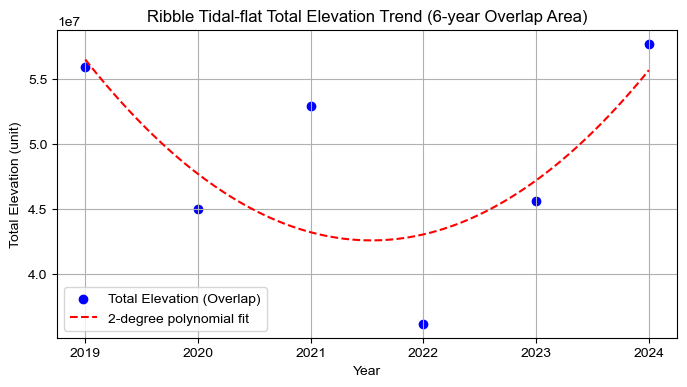

Polynomial coefficients (highest degree first): [ 2.16660034e+06 -8.75973013e+09  8.85410655e+12]


In [92]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt

year_list = [2019, 2020, 2021, 2022, 2023, 2024]
dems = []

# 1️⃣ 读取所有DEM
for year in year_list:
    path = f'G:/ICESat-2/Region4_map/Morecambe_map/A{year}/Morecambe_{year}_4_RF_FB6_new9_bys.tif'
    # path = fr'G:\ICESat-2\Region5_map\Region5b_map\A{year}\Region5b_{year}_clipped.tif'
    DEM = rxr.open_rasterio(path, masked=True).squeeze()
    dems.append(DEM)

# 2️⃣ 计算重叠掩膜（所有DEM有效值交集）
mask = np.ones_like(dems[0], dtype=bool)  # 初始化全True
for DEM in dems:
    mask &= (~np.isnan(DEM)) & (DEM != 0)

path = f'G:/ICESat-2/Region4_map/Morecambe_map/A{year}/Morecambe_{year}_4_RF_FB6_new9_bys.tif'
DEM = rxr.open_rasterio(path, masked=True).squeeze()
mask &= (~np.isnan(DEM)) & (DEM != 0)
# 3️⃣ 统计每年的总高程（只在重叠区）
sum_list = []
for DEM in dems:
    delta = DEM.where(mask)
    sum_elevation = float(delta.sum().values) * 100  # 可乘像素面积
    sum_list.append(sum_elevation)

# 4️⃣ 多项式拟合（degree=2，可改）
x = np.array(year_list)
y = np.array(sum_list)
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 100)
y_smooth = poly_func(x_smooth)

# 5️⃣ 绘图
plt.figure(figsize=(8,4))
plt.scatter(x, y, color='blue', label='Total Elevation (Overlap)')
plt.plot(x_smooth, y_smooth, color='red', linestyle='--', label=f'{degree}-degree polynomial fit')
plt.xlabel('Year')
plt.ylabel('Total Elevation (unit)')
plt.title('Ribble Tidal-flat Total Elevation Trend (6-year Overlap Area)')
plt.legend()
plt.grid(True)
plt.show()

# 输出拟合系数
print(f'Polynomial coefficients (highest degree first): {coeffs}')


Global minimum elevation across all years: -0.900 m


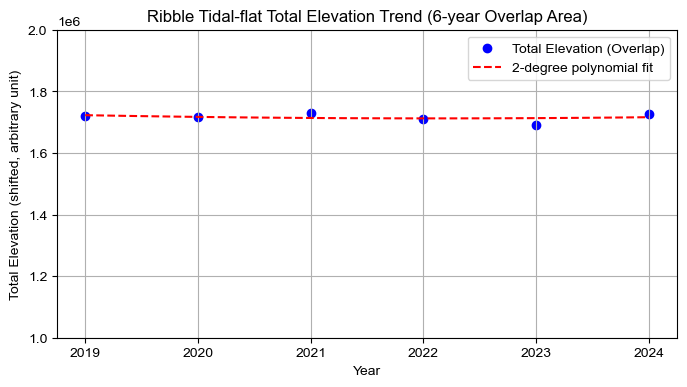

Polynomial coefficients (highest degree first): [ 1.07420536e+03 -4.34432513e+06  4.39406617e+09]


In [123]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt

year_list = [2019, 2020, 2021, 2022, 2023, 2024]
dems = []

# 1️⃣ 读取所有 DEM
for year in year_list:
    path = f'G:/ICESat-2/Region4_map/Ribble1_map/A{year}/Ribble1_{year}_4_RF_FB6_new9_bys.tif'
    DEM = rxr.open_rasterio(path, masked=True).squeeze()
    dems.append(DEM)

# 2️⃣ 计算所有 DEM 的全局最小值（忽略 NaN）
global_min = np.nanmin([DEM.min().values for DEM in dems])
print(f"Global minimum elevation across all years: {global_min:.3f} m")

# 3️⃣ 将所有 DEM 平移，使最小值为 0
dems_shifted = [(DEM - global_min) for DEM in dems]

# 4️⃣ 计算重叠掩膜（所有 DEM 有效值交集）
mask = np.ones_like(dems_shifted[0], dtype=bool)
for DEM in dems_shifted:
    mask &= (~np.isnan(DEM)) & (DEM != 0)

# 5️⃣ 统计每年的总高程（仅在重叠区）
sum_list = []
for DEM in dems_shifted:
    delta = DEM.where(mask)
    sum_elevation = float(delta.sum().values)  # 若想按面积，可乘以像元面积
    sum_list.append(sum_elevation)

# 6️⃣ 多项式拟合
x = np.array(year_list)
y = np.array(sum_list)
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 100)
y_smooth = poly_func(x_smooth)

# 7️⃣ 绘图
plt.figure(figsize=(8, 4))
plt.ylim(1000000, 2000000)
plt.scatter(x, y, color='blue', label='Total Elevation (Overlap)')
plt.plot(x_smooth, y_smooth, color='red', linestyle='--', label=f'{degree}-degree polynomial fit')
plt.xlabel('Year')
plt.ylabel('Total Elevation (shifted, arbitrary unit)')
plt.title('Ribble Tidal-flat Total Elevation Trend (6-year Overlap Area)')
plt.legend()
plt.grid(True)
plt.show()

# 输出拟合系数
print(f'Polynomial coefficients (highest degree first): {coeffs}')


Global minimum elevation across all years: -0.900 m


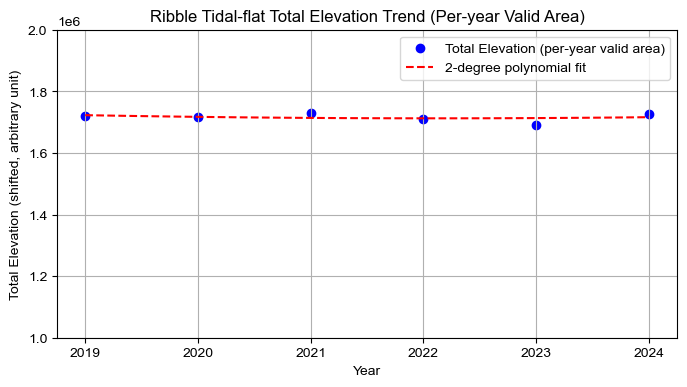

Polynomial coefficients (highest degree first): [ 1.04795982e+03 -4.23820882e+06  4.28680365e+09]
Year 2019: Total Elevation = 1718357.38, Valid Area (pixel count) = 1754459
Year 2020: Total Elevation = 1716304.12, Valid Area (pixel count) = 1754535
Year 2021: Total Elevation = 1729562.88, Valid Area (pixel count) = 1754521
Year 2022: Total Elevation = 1711647.38, Valid Area (pixel count) = 1754516
Year 2023: Total Elevation = 1691204.12, Valid Area (pixel count) = 1754521
Year 2024: Total Elevation = 1727849.62, Valid Area (pixel count) = 1754496


In [125]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt

year_list = [2019, 2020, 2021, 2022, 2023, 2024]
dems = []

# 1️⃣ 读取所有 DEM
for year in year_list:
    path = f'G:/ICESat-2/Region4_map/Ribble1_map/A{year}/Ribble1_{year}_4_RF_FB6_new9_bys.tif'
    DEM = rxr.open_rasterio(path, masked=True).squeeze()
    dems.append(DEM)

# 2️⃣ 计算所有 DEM 的全局最小值（忽略 NaN）
global_min = np.nanmin([DEM.min().values for DEM in dems])
print(f"Global minimum elevation across all years: {global_min:.3f} m")

# 3️⃣ 将所有 DEM 平移，使最小值为 0
dems_shifted = [(DEM - global_min) for DEM in dems]

# 4️⃣ 统计每年的总高程（各自有效区域）
sum_list = []
area_list = []
for DEM in dems_shifted:
    valid = (~np.isnan(DEM)) & (DEM != 0)
    delta = DEM.where(valid)
    sum_elevation = float(delta.sum().values)
    valid_area = valid.sum().values
    sum_list.append(sum_elevation)
    area_list.append(valid_area)

# 5️⃣ 多项式拟合
x = np.array(year_list)
y = np.array(sum_list)
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 100)
y_smooth = poly_func(x_smooth)

# 6️⃣ 绘图
plt.figure(figsize=(8, 4))
plt.ylim(1000000, 2000000)
plt.scatter(x, y, color='blue', label='Total Elevation (per-year valid area)')
plt.plot(x_smooth, y_smooth, color='red', linestyle='--', label=f'{degree}-degree polynomial fit')
plt.xlabel('Year')
plt.ylabel('Total Elevation (shifted, arbitrary unit)')
plt.title('Ribble Tidal-flat Total Elevation Trend (Per-year Valid Area)')
plt.legend()
plt.grid(True)
plt.show()

# 输出拟合系数和面积
print(f'Polynomial coefficients (highest degree first): {coeffs}')
for y, s, a in zip(year_list, sum_list, area_list):
    print(f'Year {y}: Total Elevation = {s:.2f}, Valid Area (pixel count) = {a}')


Global minimum elevation across all years: -0.900 m


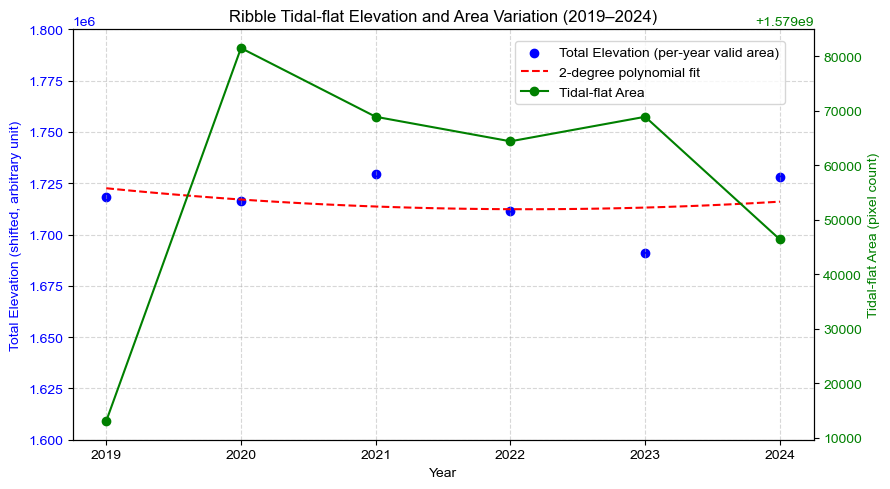

Polynomial coefficients (highest degree first): [ 1.04795982e+03 -4.23820882e+06  4.28680365e+09]
Year 2019: Total Elevation = 1718357.38, Valid Area (pixel count) = 1579013100
Year 2020: Total Elevation = 1716304.12, Valid Area (pixel count) = 1579081500
Year 2021: Total Elevation = 1729562.88, Valid Area (pixel count) = 1579068900
Year 2022: Total Elevation = 1711647.38, Valid Area (pixel count) = 1579064400
Year 2023: Total Elevation = 1691204.12, Valid Area (pixel count) = 1579068900
Year 2024: Total Elevation = 1727849.62, Valid Area (pixel count) = 1579046400


In [145]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt

# ======================================
# 1️⃣ 基本设置
# ======================================
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
dems = []

# 读取所有 DEM
for year in year_list:
    path = f'G:/ICESat-2/Region4_map/Ribble1_map/A{year}/Ribble1_{year}_4_RF_FB6_new9_bys.tif'
    DEM = rxr.open_rasterio(path, masked=True).squeeze()
    dems.append(DEM)

# ======================================
# 2️⃣ 全局最小值 + 偏移
# ======================================
global_min = np.nanmin([DEM.min().values for DEM in dems])
print(f"Global minimum elevation across all years: {global_min:.3f} m")

dems_shifted = [(DEM - global_min) for DEM in dems]

# ======================================
# 3️⃣ 统计每年总高程与有效面积
# ======================================
sum_list = []
area_list = []

for DEM in dems_shifted:
    valid = (~np.isnan(DEM)) & (DEM != 0)
    delta = DEM.where(valid)
    sum_elevation = float(delta.sum().values)
    valid_area = valid.sum().values
    sum_list.append(sum_elevation)
    area_list.append(valid_area*900)

# ======================================
# 4️⃣ 多项式拟合（高程趋势）
# ======================================
x = np.array(year_list)
y = np.array(sum_list)
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 100)
y_smooth = poly_func(x_smooth)

# ======================================
# 5️⃣ 绘图：双坐标轴
# ======================================
fig, ax1 = plt.subplots(figsize=(9, 5))

# ---- 主 y 轴：总高程 ----
ax1.set_ylim(1600000, 1800000)
ax1.scatter(x, y, color='blue', label='Total Elevation (per-year valid area)')
ax1.plot(x_smooth, y_smooth, color='red', linestyle='--', label=f'{degree}-degree polynomial fit')
ax1.set_xlabel('Year')
ax1.set_ylabel('Total Elevation (shifted, arbitrary unit)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.grid(True, which='major', linestyle='--', alpha=0.5)

# ---- 副 y 轴：面积 ----
ax2 = ax1.twinx()
ax2.plot(year_list, area_list, color='green', marker='o', label='Tidal-flat Area')
ax2.set_ylabel('Tidal-flat Area (pixel count)', color='green')
ax2.tick_params(axis='y', labelcolor='green')

# ---- 标题与图例 ----
plt.title('Ribble Tidal-flat Elevation and Area Variation (2019–2024)')
fig.legend(loc='upper left', bbox_to_anchor=(0.57, 0.92))

plt.tight_layout()
plt.show()

# ======================================
# 6️⃣ 输出结果
# ======================================
print(f'Polynomial coefficients (highest degree first): {coeffs}')
for y_, s, a in zip(year_list, sum_list, area_list):
    print(f'Year {y_}: Total Elevation = {s:.2f}, Valid Area (pixel count) = {a}')


Global minimum elevation across all years: -0.900 m

2019: valid pixels = 68240, min=0.000, max=4.280

2020: valid pixels = 68993, min=0.000, max=4.280

2021: valid pixels = 70914, min=0.000, max=4.282

2022: valid pixels = 67079, min=0.000, max=4.280

2023: valid pixels = 58047, min=0.000, max=4.279

2024: valid pixels = 67609, min=0.000, max=4.278


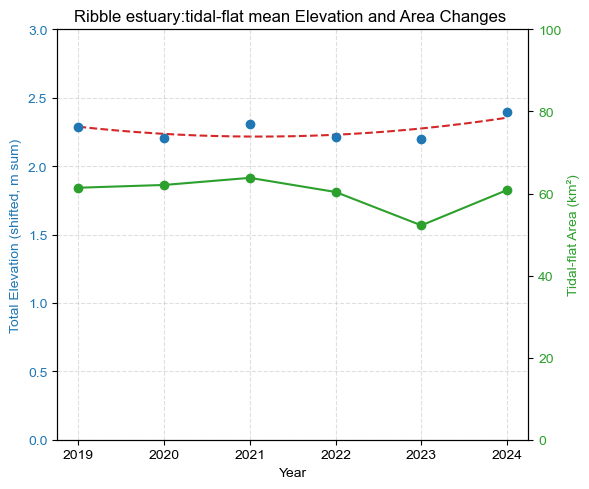


Year | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)
2019 |                      2.28 |           68240 |   61.416
2020 |                      2.20 |           68993 |   62.094
2021 |                      2.31 |           70914 |   63.823
2022 |                      2.21 |           67079 |   60.371
2023 |                      2.20 |           58047 |   52.242
2024 |                      2.40 |           67609 |   60.848


In [12]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 参数 ----------
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
base_path = r'G:/ICESat-2/Region4_map/Ribble1_map'
fname_template = 'Ribble1_{year}_4_RF_FB6_new9_bys.tif'

dems = []
for year in year_list:
    path = os.path.join(base_path, f'A{year}', fname_template.format(year=year))
    dem = rxr.open_rasterio(path, masked=True).squeeze()

    # 若没有 NaN，则尝试根据 nodata 属性重置掩膜
    nodata = dem.rio.nodata
    if nodata is not None:
        dem = dem.where(dem != nodata)

    # 再次确保 float 类型
    dem = dem.astype(float)
    dems.append(dem)

# ---------- 全局最小值 & 偏移 ----------
global_min = np.nanmin([float(dem.min().values) for dem in dems])
print(f"Global minimum elevation across all years: {global_min:.3f} m")

# ---------- 获取像元面积 ----------
xres, yres = dems[0].rio.resolution()
pixel_area_m2 = abs(xres * yres)

sum_list, pixel_count, area_m2_list = [], [], []

for year, dem in zip(year_list, dems):
    arr = dem.values

    # 掩膜：非 NaN 且绝对值大于阈值（排除0和接近0）
    valid_mask = np.isfinite(arr) & (arr > -1 )#(np.abs(arr) > 1e-6)
    valid_vals = arr[valid_mask]

    # 统计信息（用于检查）
    print(f"\n{year}: valid pixels = {np.count_nonzero(valid_mask)}, "
          f"min={np.nanmin(valid_vals):.3f}, max={np.nanmax(valid_vals):.3f}")

    shifted_vals = valid_vals# - global_min
    total_elev = np.nanmean(shifted_vals)
    n_pixels = np.count_nonzero(valid_mask)
    area_m2 = n_pixels * pixel_area_m2

    sum_list.append(total_elev)
    pixel_count.append(n_pixels)
    area_m2_list.append(area_m2)

# ---------- 多项式拟合 ----------
x = np.array(year_list)
y = np.array(sum_list)
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = poly_func(x_smooth)

# ---------- 绘图 ----------
fig, ax1 = plt.subplots(figsize=(6, 5))
ax1.set_ylim(0, 3)
ax1.scatter(x, y, color='tab:blue', label='Total Elevation (shifted sum)',zorder=2)
ax1.plot(x_smooth, y_smooth, color='tab:red', linestyle='--', label='Poly fit (2nd order)',zorder=1)
ax1.set_xlabel('Year')
ax1.set_ylabel('Total Elevation (shifted, m sum)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, linestyle='--', alpha=0.4)

ax2 = ax1.twinx()
ax2.set_ylim(0, 100)
area_km2 = np.array(area_m2_list) / 1e6
ax2.plot(year_list, area_km2, color='tab:green', marker='o', label='Tidal-flat Area (km²)',zorder=3)
ax2.set_ylabel('Tidal-flat Area (km²)', color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
# ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title('Ribble estuary:tidal-flat mean Elevation and Area Changes ')
plt.tight_layout()
plt.show()

# ---------- 输出表格 ----------
print("\nYear | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)")
for y_, s, n, a in zip(year_list, sum_list, pixel_count, area_m2_list):
    print(f"{y_:4d} | {s:25.2f} | {n:15d} | {a/1e6:8.3f}")


Global minimum elevation across all years: -1.993 m

2019: valid pixels = 223972, min=0.000, max=4.199

2020: valid pixels = 186276, min=0.000, max=4.202

2021: valid pixels = 183112, min=0.000, max=4.203

2022: valid pixels = 179284, min=0.000, max=4.197

2023: valid pixels = 179694, min=0.000, max=4.200

2024: valid pixels = 212444, min=0.000, max=4.201


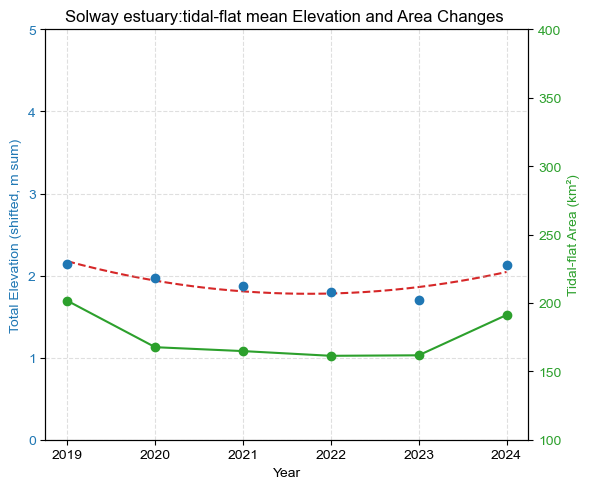


Year | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)
2019 |                      2.14 |          223972 |  201.575
2020 |                      1.97 |          186276 |  167.648
2021 |                      1.87 |          183112 |  164.801
2022 |                      1.80 |          179284 |  161.356
2023 |                      1.70 |          179694 |  161.725
2024 |                      2.13 |          212444 |  191.200


In [10]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 参数 ----------
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
base_path = r'G:/ICESat-2/Region4_map/Solway_map'
fname_template = 'Solway_{year}_4_RF_FB6_new9_bys.tif'

dems = []
for year in year_list:
    path = os.path.join(base_path, f'A{year}', fname_template.format(year=year))
    dem = rxr.open_rasterio(path, masked=True).squeeze()

    # 若没有 NaN，则尝试根据 nodata 属性重置掩膜
    nodata = dem.rio.nodata
    if nodata is not None:
        dem = dem.where(dem != nodata)

    # 再次确保 float 类型
    dem = dem.astype(float)
    dems.append(dem)

# ---------- 全局最小值 & 偏移 ----------
global_min = np.nanmin([float(dem.min().values) for dem in dems])
print(f"Global minimum elevation across all years: {global_min:.3f} m")

# ---------- 获取像元面积 ----------
xres, yres = dems[0].rio.resolution()
pixel_area_m2 = abs(xres * yres)

sum_list, pixel_count, area_m2_list = [], [], []

for year, dem in zip(year_list, dems):
    arr = dem.values

    # 掩膜：非 NaN 且绝对值大于阈值（排除0和接近0）
    valid_mask = np.isfinite(arr) & (arr > 0)#(np.abs(arr) > 1e-6)
    valid_vals = arr[valid_mask]

    # 统计信息（用于检查）
    print(f"\n{year}: valid pixels = {np.count_nonzero(valid_mask)}, "
          f"min={np.nanmin(valid_vals):.3f}, max={np.nanmax(valid_vals):.3f}")

    shifted_vals = valid_vals# - global_min
    total_elev = np.nanmean(shifted_vals)
    n_pixels = np.count_nonzero(valid_mask)
    area_m2 = n_pixels * pixel_area_m2

    sum_list.append(total_elev)
    pixel_count.append(n_pixels)
    area_m2_list.append(area_m2)

# ---------- 多项式拟合 ----------
x = np.array(year_list)
y = np.array(sum_list)
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = poly_func(x_smooth)

# ---------- 绘图 ----------
fig, ax1 = plt.subplots(figsize=(6, 5))
ax1.set_ylim(0, 5)
ax1.scatter(x, y, color='tab:blue', label='Total Elevation (shifted sum)',zorder=2)
ax1.plot(x_smooth, y_smooth, color='tab:red', linestyle='--', label='Poly fit (2nd order)',zorder=1)
ax1.set_xlabel('Year')
ax1.set_ylabel('Total Elevation (shifted, m sum)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, linestyle='--', alpha=0.4)

ax2 = ax1.twinx()
ax2.set_ylim(100, 400)
area_km2 = np.array(area_m2_list) / 1e6
ax2.plot(year_list, area_km2, color='tab:green', marker='o', label='Tidal-flat Area (km²)',zorder=3)
ax2.set_ylabel('Tidal-flat Area (km²)', color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
# ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title('Solway estuary:tidal-flat mean Elevation and Area Changes ')
plt.tight_layout()
plt.show()

# ---------- 输出表格 ----------
print("\nYear | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)")
for y_, s, n, a in zip(year_list, sum_list, pixel_count, area_m2_list):
    print(f"{y_:4d} | {s:25.2f} | {n:15d} | {a/1e6:8.3f}")


Global minimum elevation across all years: -1.272 m

2019: valid pixels = 307371, min=0.000, max=4.201

2020: valid pixels = 298961, min=0.000, max=4.167

2021: valid pixels = 296025, min=0.000, max=4.228

2022: valid pixels = 258193, min=0.000, max=4.224

2023: valid pixels = 287143, min=0.000, max=4.133

2024: valid pixels = 305929, min=0.000, max=4.232


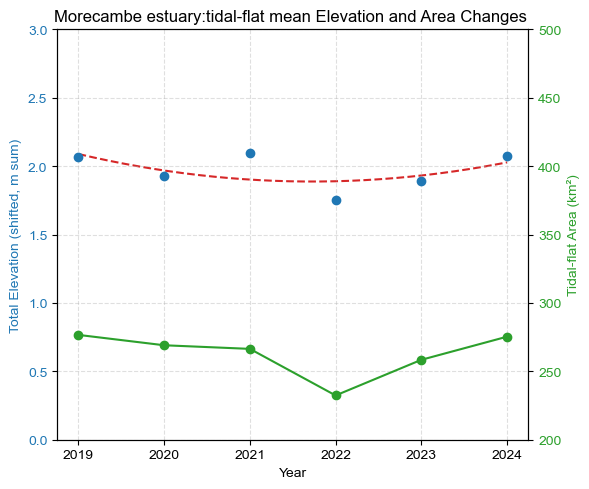


Year | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)
2019 |                      2.07 |          307371 |  276.634
2020 |                      1.93 |          298961 |  269.065
2021 |                      2.09 |          296025 |  266.423
2022 |                      1.75 |          258193 |  232.374
2023 |                      1.89 |          287143 |  258.429
2024 |                      2.08 |          305929 |  275.336


In [8]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 参数 ----------
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
base_path = r'G:/ICESat-2/Region4_map/Morecambe_map'
fname_template = 'Morecambe_{year}_4_RF_FB6_new9_bys.tif'

dems = []
for year in year_list:
    path = os.path.join(base_path, f'A{year}', fname_template.format(year=year))
    dem = rxr.open_rasterio(path, masked=True).squeeze()

    # 若没有 NaN，则尝试根据 nodata 属性重置掩膜
    nodata = dem.rio.nodata
    if nodata is not None:
        dem = dem.where(dem != nodata)

    # 再次确保 float 类型
    dem = dem.astype(float)
    dems.append(dem)

# ---------- 全局最小值 & 偏移 ----------
global_min = np.nanmin([float(dem.min().values) for dem in dems])
print(f"Global minimum elevation across all years: {global_min:.3f} m")

# ---------- 获取像元面积 ----------
xres, yres = dems[0].rio.resolution()
pixel_area_m2 = abs(xres * yres)

sum_list, pixel_count, area_m2_list = [], [], []

for year, dem in zip(year_list, dems):
    arr = dem.values

    # 掩膜：非 NaN 且绝对值大于阈值（排除0和接近0）
    valid_mask = np.isfinite(arr) & (arr > 0)#(np.abs(arr) > 1e-6)
    valid_vals = arr[valid_mask]

    # 统计信息（用于检查）
    print(f"\n{year}: valid pixels = {np.count_nonzero(valid_mask)}, "
          f"min={np.nanmin(valid_vals):.3f}, max={np.nanmax(valid_vals):.3f}")

    shifted_vals = valid_vals #- global_min
    total_elev = np.nanmean(shifted_vals)
    n_pixels = np.count_nonzero(valid_mask)
    area_m2 = n_pixels * pixel_area_m2

    sum_list.append(total_elev)
    pixel_count.append(n_pixels)
    area_m2_list.append(area_m2)

# ---------- 多项式拟合 ----------
x = np.array(year_list)
y = np.array(sum_list)
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = poly_func(x_smooth)

# ---------- 绘图 ----------
fig, ax1 = plt.subplots(figsize=(6, 5))
ax1.set_ylim(0, 3)
ax1.scatter(x, y, color='tab:blue', label='Total Elevation (shifted sum)',zorder=2)
ax1.plot(x_smooth, y_smooth, color='tab:red', linestyle='--', label='Poly fit (2nd order)',zorder=1)
ax1.set_xlabel('Year')
ax1.set_ylabel('Total Elevation (shifted, m sum)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, linestyle='--', alpha=0.4)

ax2 = ax1.twinx()
ax2.set_ylim(200, 500)
area_km2 = np.array(area_m2_list) / 1e6
ax2.plot(year_list, area_km2, color='tab:green', marker='o', label='Tidal-flat Area (km²)',zorder=3)
ax2.set_ylabel('Tidal-flat Area (km²)', color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
# ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title('Morecambe estuary:tidal-flat mean Elevation and Area Changes ')
plt.tight_layout()
plt.show()

# ---------- 输出表格 ----------
print("\nYear | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)")
for y_, s, n, a in zip(year_list, sum_list, pixel_count, area_m2_list):
    print(f"{y_:4d} | {s:25.2f} | {n:15d} | {a/1e6:8.3f}")

Global minimum elevation across all years: -2.264 m

2019: valid pixels = 132027, min=0.000, max=3.634

2020: valid pixels = 119109, min=0.000, max=3.643

2021: valid pixels = 144808, min=0.000, max=3.640

2022: valid pixels = 144574, min=0.000, max=3.640

2023: valid pixels = 118886, min=0.000, max=3.462

2024: valid pixels = 131642, min=0.000, max=3.643


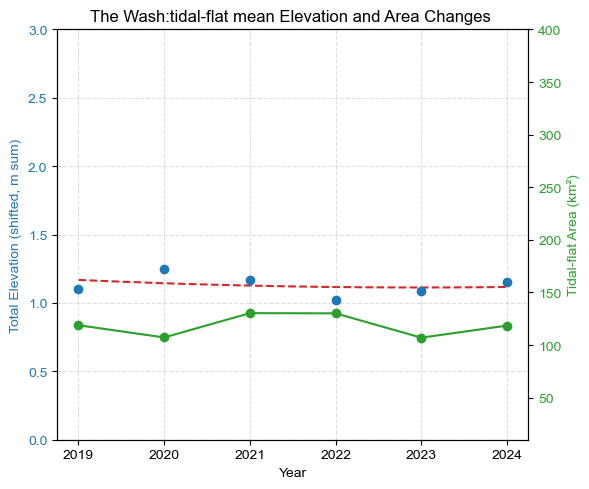


Year | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)
2019 |                      1.10 |          132027 |  118.824
2020 |                      1.25 |          119109 |  107.198
2021 |                      1.17 |          144808 |  130.327
2022 |                      1.02 |          144574 |  130.117
2023 |                      1.09 |          118886 |  106.997
2024 |                      1.15 |          131642 |  118.478


In [16]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 参数 ----------
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
base_path = r'G:/ICESat-2/Region2_map/wash_bay_map'
fname_template = 'wash_bay_{year}_4_RF_FB6_new9_bys.tif'

dems = []
for year in year_list:
    path = os.path.join(base_path, f'A{year}', fname_template.format(year=year))
    dem = rxr.open_rasterio(path, masked=True).squeeze()

    # 若没有 NaN，则尝试根据 nodata 属性重置掩膜
    nodata = dem.rio.nodata
    if nodata is not None:
        dem = dem.where(dem != nodata)

    # 再次确保 float 类型
    dem = dem.astype(float)
    dems.append(dem)

# ---------- 全局最小值 & 偏移 ----------
global_min = np.nanmin([float(dem.min().values) for dem in dems])
print(f"Global minimum elevation across all years: {global_min:.3f} m")

# ---------- 获取像元面积 ----------
xres, yres = dems[0].rio.resolution()
pixel_area_m2 = abs(xres * yres)

sum_list, pixel_count, area_m2_list = [], [], []

for year, dem in zip(year_list, dems):
    arr = dem.values

    # 掩膜：非 NaN 且绝对值大于阈值（排除0和接近0）
    valid_mask = np.isfinite(arr) & (arr > 0 )#(np.abs(arr) > 1e-6)
    valid_vals = arr[valid_mask]

    # 统计信息（用于检查）
    print(f"\n{year}: valid pixels = {np.count_nonzero(valid_mask)}, "
          f"min={np.nanmin(valid_vals):.3f}, max={np.nanmax(valid_vals):.3f}")

    shifted_vals = valid_vals #- global_min
    total_elev = np.nanmean(shifted_vals)
    n_pixels = np.count_nonzero(valid_mask)
    area_m2 = n_pixels * pixel_area_m2

    sum_list.append(total_elev)
    pixel_count.append(n_pixels)
    area_m2_list.append(area_m2)

# ---------- 多项式拟合 ----------
x = np.array(year_list)
y = np.array(sum_list)
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = poly_func(x_smooth)

# ---------- 绘图 ----------
fig, ax1 = plt.subplots(figsize=(6, 5))
ax1.set_ylim(0, 3)
ax1.scatter(x, y, color='tab:blue', label='Total Elevation (shifted sum)',zorder=2)
ax1.plot(x_smooth, y_smooth, color='tab:red', linestyle='--', label='Poly fit (2nd order)',zorder=1)
ax1.set_xlabel('Year')
ax1.set_ylabel('Total Elevation (shifted, m sum)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, linestyle='--', alpha=0.4)

ax2 = ax1.twinx()
ax2.set_ylim(10, 400)
area_km2 = np.array(area_m2_list) / 1e6
ax2.plot(year_list, area_km2, color='tab:green', marker='o', label='Tidal-flat Area (km²)',zorder=3)
ax2.set_ylabel('Tidal-flat Area (km²)', color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
# ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title('The Wash:tidal-flat mean Elevation and Area Changes ')
plt.tight_layout()
plt.show()

# ---------- 输出表格 ----------
print("\nYear | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)")
for y_, s, n, a in zip(year_list, sum_list, pixel_count, area_m2_list):
    print(f"{y_:4d} | {s:25.2f} | {n:15d} | {a/1e6:8.3f}")

Global minimum elevation across all years: -2.076 m

2019: valid pixels = 66635, min=0.000, max=3.273

2020: valid pixels = 79748, min=0.000, max=3.248

2021: valid pixels = 75006, min=0.000, max=3.302

2022: valid pixels = 73317, min=0.000, max=3.306

2023: valid pixels = 75593, min=0.000, max=3.312

2024: valid pixels = 70828, min=0.000, max=3.327


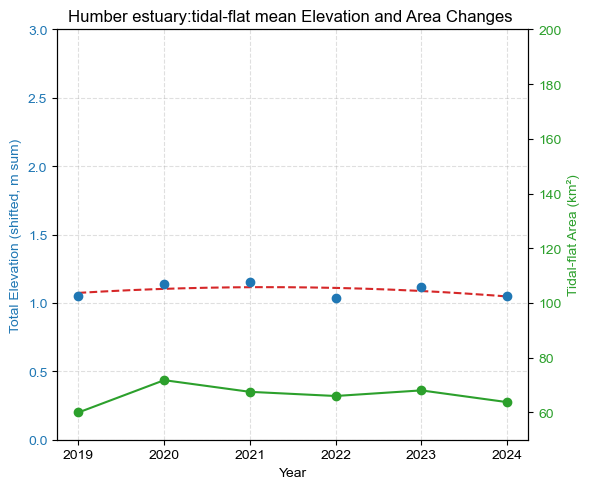


Year | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)
2019 |                      1.05 |           66635 |   59.971
2020 |                      1.14 |           79748 |   71.773
2021 |                      1.15 |           75006 |   67.505
2022 |                      1.03 |           73317 |   65.985
2023 |                      1.11 |           75593 |   68.034
2024 |                      1.05 |           70828 |   63.745


In [ ]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 参数 ----------
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
base_path = r'G:/ICESat-2/Region1_map/Thames_map'
fname_template = 'Henber_{year}_4_RF_FB6_new9_bys_Join2.tif'

dems = []
for year in year_list:
    path = os.path.join(base_path, f'A{year}', fname_template.format(year=year))
    dem = rxr.open_rasterio(path, masked=True).squeeze()

    # 若没有 NaN，则尝试根据 nodata 属性重置掩膜
    nodata = dem.rio.nodata
    if nodata is not None:
        dem = dem.where(dem != nodata)

    # 再次确保 float 类型
    dem = dem.astype(float)
    dems.append(dem)

# ---------- 全局最小值 & 偏移 ----------
global_min = np.nanmin([float(dem.min().values) for dem in dems])
print(f"Global minimum elevation across all years: {global_min:.3f} m")

# ---------- 获取像元面积 ----------
xres, yres = dems[0].rio.resolution()
pixel_area_m2 = abs(xres * yres)

sum_list, pixel_count, area_m2_list = [], [], []

for year, dem in zip(year_list, dems):
    arr = dem.values

    # 掩膜：非 NaN 且绝对值大于阈值（排除0和接近0）
    valid_mask = np.isfinite(arr) & (arr > 0)#(np.abs(arr) > 1e-6)
    valid_vals = arr[valid_mask]

    # 统计信息（用于检查）
    print(f"\n{year}: valid pixels = {np.count_nonzero(valid_mask)}, "
          f"min={np.nanmin(valid_vals):.3f}, max={np.nanmax(valid_vals):.3f}")

    shifted_vals = valid_vals #- global_min
    total_elev = np.nanmean(shifted_vals)
    n_pixels = np.count_nonzero(valid_mask)
    area_m2 = n_pixels * pixel_area_m2

    sum_list.append(total_elev)
    pixel_count.append(n_pixels)
    area_m2_list.append(area_m2)

# ---------- 多项式拟合 ----------
x = np.array(year_list)
y = np.array(sum_list)
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = poly_func(x_smooth)

# ---------- 绘图 ----------
fig, ax1 = plt.subplots(figsize=(6, 5))
ax1.set_ylim(0, 3)
ax1.scatter(x, y, color='tab:blue', label='Total Elevation (shifted sum)',zorder=2)
ax1.plot(x_smooth, y_smooth, color='tab:red', linestyle='--', label='Poly fit (2nd order)',zorder=1)
ax1.set_xlabel('Year')
ax1.set_ylabel('Total Elevation (shifted, m sum)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, linestyle='--', alpha=0.4)

ax2 = ax1.twinx()
ax2.set_ylim(50,200)
area_km2 = np.array(area_m2_list) / 1e6
ax2.plot(year_list, area_km2, color='tab:green', marker='o', label='Tidal-flat Area (km²)',zorder=3)
ax2.set_ylabel('Tidal-flat Area (km²)', color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
# ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title('Humber estuary:tidal-flat mean Elevation and Area Changes ')
plt.tight_layout()
plt.show()

# ---------- 输出表格 ----------
print("\nYear | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)")
for y_, s, n, a in zip(year_list, sum_list, pixel_count, area_m2_list):
    print(f"{y_:4d} | {s:25.2f} | {n:15d} | {a/1e6:8.3f}")

Global minimum elevation across all years: -1.595 m

2019: valid pixels = 59802, min=0.000, max=4.609

2020: valid pixels = 49032, min=0.000, max=4.683

2021: valid pixels = 39230, min=0.000, max=4.653

2022: valid pixels = 54908, min=0.000, max=4.795

2023: valid pixels = 70767, min=0.000, max=4.777

2024: valid pixels = 53156, min=0.000, max=4.516


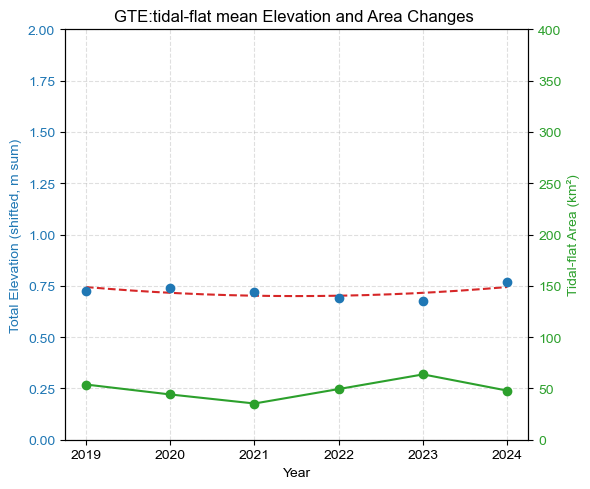


Year | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)
2019 |                      0.72 |           59802 |   53.822
2020 |                      0.74 |           49032 |   44.129
2021 |                      0.72 |           39230 |   35.307
2022 |                      0.69 |           54908 |   49.417
2023 |                      0.68 |           70767 |   63.690
2024 |                      0.77 |           53156 |   47.840


In [14]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 参数 ----------
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
base_path = r'G:/ICESat-2/Region1_map/Thames1_map'
fname_template = 'Thames1_{year}_4_RF_FB6_new9_bys.tif'

dems = []
for year in year_list:
    path = os.path.join(base_path, f'A{year}', fname_template.format(year=year))
    dem = rxr.open_rasterio(path, masked=True).squeeze()

    # 若没有 NaN，则尝试根据 nodata 属性重置掩膜
    nodata = dem.rio.nodata
    if nodata is not None:
        dem = dem.where(dem != nodata)

    # 再次确保 float 类型
    dem = dem.astype(float)
    dems.append(dem)

# ---------- 全局最小值 & 偏移 ----------
global_min = np.nanmin([float(dem.min().values) for dem in dems])
print(f"Global minimum elevation across all years: {global_min:.3f} m")

# ---------- 获取像元面积 ----------
xres, yres = dems[0].rio.resolution()
pixel_area_m2 = abs(xres * yres)

sum_list, pixel_count, area_m2_list = [], [], []

for year, dem in zip(year_list, dems):
    arr = dem.values

    # 掩膜：非 NaN 且绝对值大于阈值（排除0和接近0）
    valid_mask = np.isfinite(arr) & (arr > 0)# & np.abs(arr) > 1e-6
    valid_vals = arr[valid_mask]

    # 统计信息（用于检查）
    print(f"\n{year}: valid pixels = {np.count_nonzero(valid_mask)}, "
          f"min={np.nanmin(valid_vals):.3f}, max={np.nanmax(valid_vals):.3f}")

    shifted_vals = valid_vals# - global_min
    total_elev = np.nanmean(shifted_vals)
    n_pixels = np.count_nonzero(valid_mask)
    area_m2 = n_pixels * pixel_area_m2

    sum_list.append(total_elev)
    pixel_count.append(n_pixels)
    area_m2_list.append(area_m2)

# ---------- 多项式拟合 ----------
x = np.array(year_list)
y = np.array(sum_list)
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = poly_func(x_smooth)

# ---------- 绘图 ----------
fig, ax1 = plt.subplots(figsize=(6, 5))
ax1.set_ylim(0, 2)
ax1.scatter(x, y, color='tab:blue', label='Total Elevation (shifted sum)',zorder=2)
ax1.plot(x_smooth, y_smooth, color='tab:red', linestyle='--', label='Poly fit (2nd order)',zorder=1)
ax1.set_xlabel('Year')
ax1.set_ylabel('Total Elevation (shifted, m sum)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, linestyle='--', alpha=0.4)

ax2 = ax1.twinx()
ax2.set_ylim(0,400)
area_km2 = np.array(area_m2_list) / 1e6
ax2.plot(year_list, area_km2, color='tab:green', marker='o', label='Tidal-flat Area (km²)',zorder=3)
ax2.set_ylabel('Tidal-flat Area (km²)', color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
# ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title('GTE:tidal-flat mean Elevation and Area Changes ')
plt.tight_layout()
plt.show()

# ---------- 输出表格 ----------
print("\nYear | Total Elevation (shifted sum, m) | Non-zero pixels | Area (km²)")
for y_, s, n, a in zip(year_list, sum_list, pixel_count, area_m2_list):
    print(f"{y_:4d} | {s:25.2f} | {n:15d} | {a/1e6:8.3f}")


Common valid region pixels (intersection of all years): 6953296

Year | Mean Elevation (shifted, m) | Overlap pixels | Area (km²)
2019 |                        0.035 |          278358 |  250.522
2020 |                       -0.007 |          257132 |  231.419
2021 |                       -0.079 |          281819 |  253.637
2022 |                        0.063 |          267020 |  240.318
2023 |                        0.180 |          264783 |  238.305
2024 |                        0.059 |          260169 |  234.152


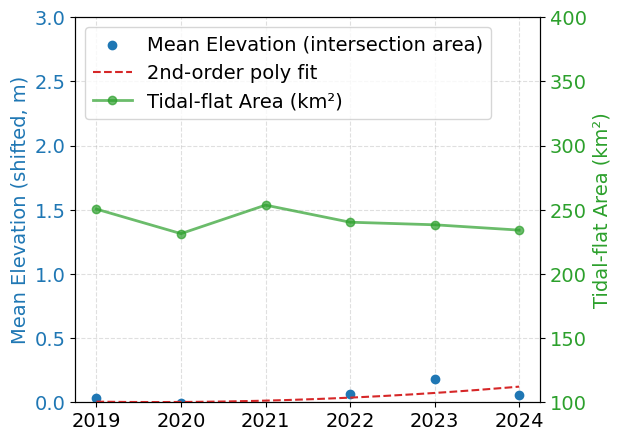

In [8]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 参数 ----------
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
base_path = r'G:/ICESat-2/Region1_map/Thames_map'
fname_template = 'Thames_{year}_4_RF_FB6_new9_bys.tif'

dems = []
for year in year_list:
    path = os.path.join(base_path, f'A{year}', fname_template.format(year=year))
    dem = rxr.open_rasterio(path, masked=True).squeeze()

    # 若没有 NaN，则根据 nodata 属性重置掩膜
    nodata = dem.rio.nodata
    if nodata is not None:
        dem = dem.where(dem != nodata)

    dem = dem.astype(float)
    dems.append(dem)


# ---------- 获取像元面积 ----------
xres, yres = dems[0].rio.resolution()
pixel_area_m2 = abs(xres * yres)

# ---------- 计算所有年份的有效区交集 ----------
valid_mask = np.ones_like(dems[0].values, dtype=bool)
for dem in dems:
    arr = dem.values
    # valid_mask = np.isfinite(arr) & (arr != 0)


# 检查交集有效像元数
print(f"\nCommon valid region pixels (intersection of all years): {np.count_nonzero(valid_mask)}")

# ---------- 在交集区域内计算每年的均值 & 面积 ----------
sum_list, pixel_count, area_m2_list = [], [], []
for year, dem in zip(year_list, dems):
    arr = dem.values
    shifted_vals = arr[np.isfinite(arr) & (arr != 0)]
    shifted_vals = shifted_vals[shifted_vals>-1]
    
    total_elev = np.nanmean(shifted_vals)
    n_pixels = np.count_nonzero(shifted_vals)
    area_m2 = n_pixels * pixel_area_m2

    sum_list.append(total_elev)
    pixel_count.append(n_pixels)
    area_m2_list.append(area_m2)

# ---------- 多项式拟合 ----------
x = np.array(year_list)
y = np.array(sum_list)
degree = 2
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = poly_func(x_smooth)

# ---------- 绘图 ----------

fig, ax1 = plt.subplots(figsize=(6, 5))
ax1.set_ylim(0, 3)
ax1.scatter(x, y, color='tab:blue', label='Mean Elevation (intersection area)', zorder=3)
ax1.plot(x_smooth, y_smooth, color='tab:red', linestyle='--', label='2nd-order poly fit', zorder=4)
# ax1.set_xlabel('Year')
ax1.set_ylabel('Mean Elevation (shifted, m)', color='tab:blue', fontsize = 14)
ax1.tick_params(axis='y', labelcolor='tab:blue', labelsize = 14)
ax1.tick_params(axis='x',  labelsize = 14)
ax1.grid(True, linestyle='--', alpha=0.4)



# ---------- 面积曲线（右轴） ----------
ax2 = ax1.twinx()
ax2.set_ylim(100, 400)
area_km2 = np.array(area_m2_list) / 1e6
ax2.plot(year_list, area_km2, color='tab:green', marker='o',
         alpha=0.7, linewidth=2, label='Tidal-flat Area (km²)', zorder=2)
ax2.set_ylabel('Tidal-flat Area (km²)', color='tab:green', fontsize = 14)
ax2.tick_params(axis='y', labelcolor='tab:green', labelsize = 14)

# ---------- 图例与标题 ----------
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left',fontsize = 14)

# plt.title('Morecambe bay: Mean Elevation and Tidal-flat area', fontsize = 14)
# plt.tight_layout()
# plt.show()

# ---------- 输出表格 ----------
print("\nYear | Mean Elevation (shifted, m) | Overlap pixels | Area (km²)")
for y_, s, n, a in zip(year_list, sum_list, pixel_count, area_m2_list):
    print(f"{y_:4d} | {s:28.3f} | {n:15d} | {a/1e6:8.3f}")



Common valid region pixels (intersection of all years): 330850


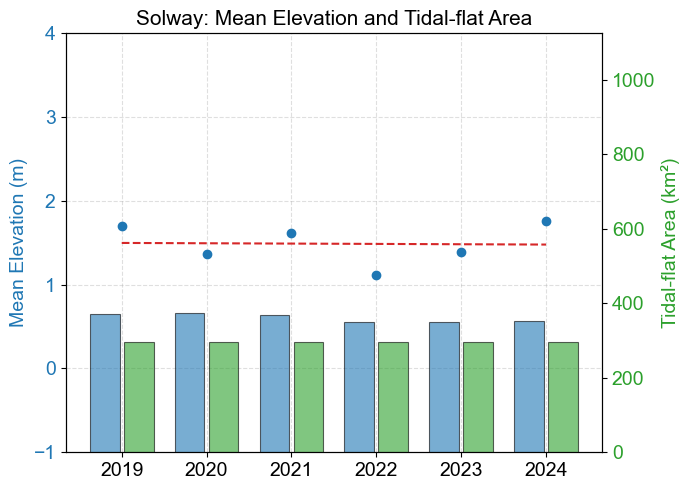


Year | Mean Elevation (m) | Overlap pixels | Area (km²)
2019 |              1.699 |          329805 |  370.139
2020 |              1.362 |          330498 |  375.016
2021 |              1.614 |          329101 |  368.639
2022 |              1.114 |          327582 |  349.227
2023 |              1.386 |          329843 |  350.186
2024 |              1.757 |          329438 |  351.789


In [75]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 参数 ----------
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
base_path = r'G:/ICESat-2/Region4_map/Morecambe_map'
fname_template = 'Morecambe_{year}_4_RF_FB6_new9_bys.tif'

dems = []
for year in year_list:
    path = os.path.join(base_path, f'A{year}', fname_template.format(year=year))
    dem = rxr.open_rasterio(path, masked=True).squeeze()

    # 若没有 NaN，则根据 nodata 属性重置掩膜
    nodata = dem.rio.nodata
    if nodata is not None:
        dem = dem.where(dem != nodata)

    dem = dem.astype(float)
    dems.append(dem)

# ---------- 获取像元面积 ----------
xres, yres = dems[0].rio.resolution()
pixel_area_m2 = abs(xres * yres)

# ---------- 计算所有年份的有效区交集 ----------
valid_mask = np.ones_like(dems[0].values, dtype=bool)
for dem in dems:
    arr = dem.values
    valid_mask &= np.isfinite(arr) & (arr != 0)

# 检查交集有效像元数
print(f"\nCommon valid region pixels (intersection of all years): {np.count_nonzero(valid_mask)}")

# ---------- 在交集区域内计算每年的均值 & 面积 ----------
sum_list, pixel_count, area_m2_list, all_area = [], [], [], []
for year, dem in zip(year_list, dems):
    
    
    arr = dem.values
    arr_ = np.count_nonzero(arr[np.isfinite(arr) & (arr != 0)])
    
    shifted_vals = arr[valid_mask]
    shifted_vals = shifted_vals[shifted_vals > -1]
    
    total_elev = np.nanmean(shifted_vals)
    n_pixels = np.count_nonzero(shifted_vals)
    area_m2 = n_pixels * pixel_area_m2

    sum_list.append(total_elev)
    pixel_count.append(n_pixels)
    area_m2_list.append(area_m2)
    all_area.append(arr_*pixel_area_m2)
    
# ---------- 多项式拟合 ----------

x = np.array(year_list)
y = np.array(sum_list)
degree = 1
coeffs = np.polyfit(x, y, degree)
poly_func = np.poly1d(coeffs)
x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = poly_func(x_smooth)

# ---------- 绘图 ----------
fig, ax1 = plt.subplots(figsize=(7, 5))

# 左轴：平均高程折线
ax1.set_ylim(0, 3)
ax1.scatter(x, y, color='tab:blue', label='Mean Elevation (intersection area)', zorder=3)
# ax1.plot(x, y, color='tab:blue', marker='D', markerfacecolor='tab:blue',    # 可选：让点更清晰
#     markersize=8,   
#     linestyle='--', # 可调大小
#     linewidth=2,
#     label='Mean Elevation ',
#     zorder=3
# )
ax1.plot(x_smooth, y_smooth, color='tab:red', linestyle='--', label='2nd-order poly fit', zorder=4)
ax1.set_ylabel('Mean Elevation (m)', color='tab:blue', fontsize=14)
ax1.tick_params(axis='y', labelcolor='tab:blue', labelsize=14)
ax1.tick_params(axis='x', labelsize=14)
ax1.set_ylim(-0.5, np.max(sum_list) * 1.5)
ax1.set_ylim(-1, 4)
# ax1.set_ylim(-0.5, 0.5)
ax1.grid(True, linestyle='--', alpha=0.4)

ax2 = ax1.twinx() 
ax2.set_ylim(100, 400) 

all_area_km2 = np.array(all_area) / 1e6 
area_km2 = np.array(area_m2_list) / 1e6 

# ax2.plot(year_list, all_area_km2, color='tab:blue', marker='o', alpha=0.7, linewidth=2, label='Tidal-flat Area (km²)', zorder=2) 
# ax2.plot(year_list, area_km2, color='tab:green', marker='o', alpha=0.7, linewidth=2, label='Tidal-flat Area (km²)', zorder=2) 
bar_width = 0.35
gap = 0.05           # 两组柱子之间的间隔

# 计算偏移（确保中间留出空隙）
x1 = [y - (bar_width/2 + gap/2) for y in year_list]
x2 = [y + (bar_width/2 + gap/2) for y in year_list]

# 绘制第一组柱子（蓝色）
ax2.bar(x1, all_area_km2, 
        width=bar_width, color='tab:blue', alpha=0.6, 
        edgecolor='black', linewidth=0.8, label='Total Tidal-flat Area (km²)', zorder=2)

# 绘制第二组柱子（绿色）
ax2.bar(x2, area_km2, 
        width=bar_width, color='tab:green', alpha=0.6, 
        edgecolor='black', linewidth=0.8, label='Tidal-flat Area (km²)', zorder=2)

# 设置x轴刻度位置（使刻度仍对齐年份）
ax2.set_xticks(year_list)
ax2.set_xticklabels(year_list)


ax2.set_ylabel('Tidal-flat Area (km²)', color='tab:green', fontsize = 14) 
ax2.tick_params(axis='y', labelcolor='tab:green', labelsize = 14)
ax2.set_ylim(0, np.max(all_area_km2) * 3)
# ---------- 图例与标题 ----------
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
# ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', fontsize=13)

plt.title('Solway: Mean Elevation and Tidal-flat Area', fontsize=15)
plt.tight_layout()
plt.show()

# ---------- 输出表格 ----------
print("\nYear | Mean Elevation (m) | Overlap pixels | Area (km²)")
for y_, s, n, a in zip(year_list, sum_list, pixel_count, all_area):
    print(f"{y_:4d} | {s:18.3f} | {n:15d} | {a/1e6:8.3f}")


In [ ]:
import geopandas as gpd

year = 2021
path = f'G:/ICESat-2/Region4_map/Morecambe_map/A{year}/Morecambe_{year}_4_RF_FB6_new9_bys.tif'
k = rxr.open_rasterio(path).squeeze()
mask  = k!=0
k = 
k.shape

(2146, 1901)

erosion_area 302161
accretion_area 139373
all pixel 441534
2019-2020: mean Δh = -0.015 m, Erosion = 7.4%, Accretion = 3.4%
--------------------------------------------------


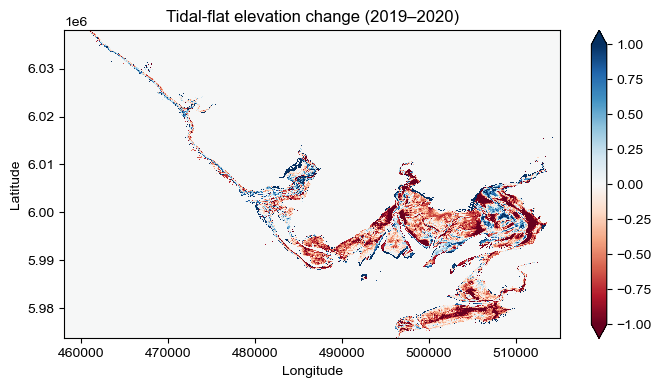

erosion_area 163322
accretion_area 277430
all pixel 440752
2020-2021: mean Δh = 0.009 m, Erosion = 4.0%, Accretion = 6.8%
--------------------------------------------------


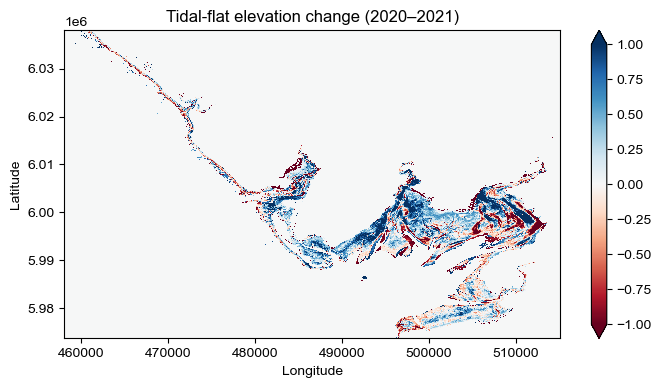

erosion_area 320328
accretion_area 102126
all pixel 422454
2021-2022: mean Δh = -0.042 m, Erosion = 7.9%, Accretion = 2.5%
--------------------------------------------------


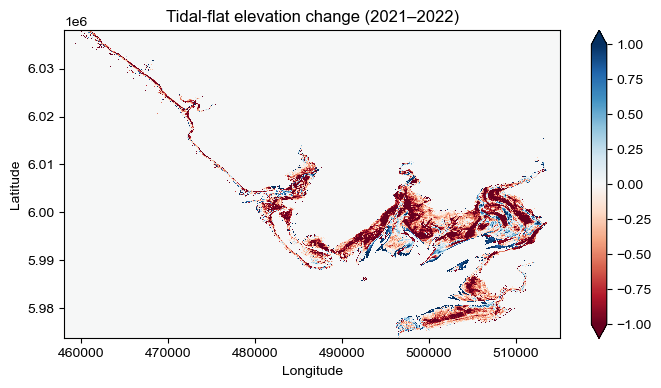

erosion_area 114051
accretion_area 298090
all pixel 412141
2022-2023: mean Δh = 0.027 m, Erosion = 2.8%, Accretion = 7.3%
--------------------------------------------------


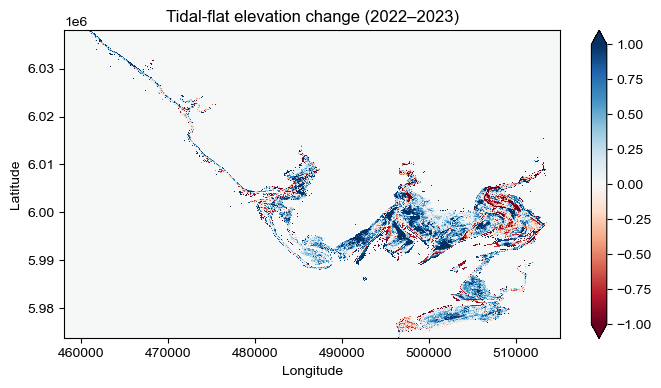

erosion_area 114901
accretion_area 298731
all pixel 413632
2023-2024: mean Δh = 0.025 m, Erosion = 2.8%, Accretion = 7.3%
--------------------------------------------------


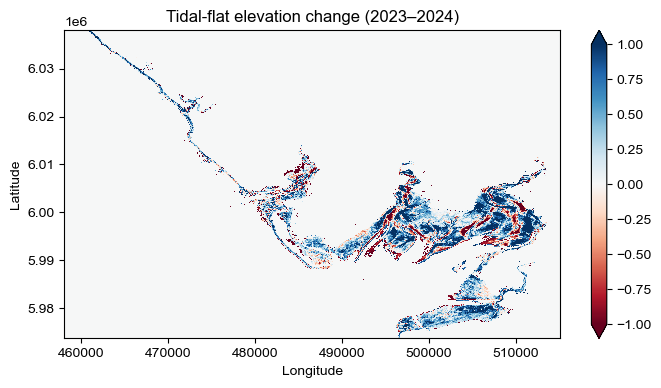

In [76]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt

# 定义年份列表
year_list = [2019, 2020, 2021, 2022, 2023]
# year_list = [2019]
# 循环计算相邻年份的差值
for year in year_list:
    year_after = year + 1
    
    path = f'G:/ICESat-2/Region4_map/Morecambe_map/A{year}/Morecambe_{year}_4_RF_FB6_new9_bys.tif'
    path_after = f'G:/ICESat-2/Region4_map/Morecambe_map/A{year_after}/Morecambe_{year_after}_4_RF_FB6_new9_bys.tif'
    
    # 读取DEM
    DEM = rxr.open_rasterio(path, masked=True).squeeze()
    DEM_after = rxr.open_rasterio(path_after, masked=True).squeeze()

    # 对齐数据
    DEM_after = DEM_after.rio.reproject_match(DEM)
    
    # 计算高程变化
    delta = DEM_after - DEM

    # 掩膜去除无效值
    delta = delta.where((~np.isnan(DEM)) & (~np.isnan(DEM_after)) )
    delta_num = np.sum((~np.isnan(DEM)) & (DEM != 0) )
#     print('delta_num',delta_num)
    # 计算统计信息
    mean_change = float(delta.mean().values)
    erosion_area = (delta < 0).sum().values
    accretion_area = (delta > 0).sum().values
    print('erosion_area',erosion_area)
    print('accretion_area',accretion_area)
    print('all pixel', ((~np.isnan(delta)) & (delta !=0)).sum().values)
    
    total_area = (~np.isnan(delta)).sum().values
    erosion_ratio = erosion_area / total_area * 100
    accretion_ratio = accretion_area / total_area * 100
    
    print(
          f'{year}-{year_after}: mean Δh = {mean_change:.3f} m, '
          f'Erosion = {erosion_ratio:.1f}%, Accretion = {accretion_ratio:.1f}%')
    
    print(50*'-')
    # 绘制差值图
    plt.figure(figsize=(8, 4))
    delta.plot(cmap='RdBu', vmin=-1, vmax=1)
    plt.title(f'Tidal-flat elevation change ({year}–{year_after})')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.show()


In [22]:
import rioxarray as rxr
import numpy as np
location = 'Morecambe'
# 定义年份列表
year_list = [2019, 2020, 2021, 2022, 2023]

for year in year_list:
    year_after = year + 1

    path = f'H:/ICESat-2/Region4_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys_C.tif'
    path_after = f'H:/ICESat-2/Region4_map/{location}_map/A{year_after}/{location}_{year_after}_4_RF_FB6_new9_bys_C.tif'

    # 读取DEM
    DEM = rxr.open_rasterio(path, masked=True).squeeze()
    DEM_after = rxr.open_rasterio(path_after, masked=True).squeeze()

    # 对齐
    DEM_after = DEM_after.rio.reproject_match(DEM)

    # 像元分辨率（单位：米）
    res_x, res_y = DEM.rio.resolution()
    pixel_area = abs(res_x * res_y)

    # 掩膜（仅保留非空、非零、正值）
    mask_1 = (~np.isnan(DEM)) & (DEM != 0) #& (DEM > 0)
    mask_2 = (~np.isnan(DEM_after)) & (DEM_after != 0) #& (DEM_after > 0)

    # 两年共同有效掩膜（用于变化统计）
    common_mask = mask_1 & mask_2

    # ---------- 年际统计 ----------
    area_1_km2 = np.sum(mask_1) * pixel_area / 1e6
    area_2_km2 = np.sum(mask_2) * pixel_area / 1e6

    mean_elev_1 = float(DEM.where(mask_1).mean().values)
    mean_elev_2 = float(DEM_after.where(mask_2).mean().values)

    # ---------- 年际变化 ----------
    delta = DEM_after - DEM
    delta = delta.where(common_mask)

    mean_elev_common_1 = float(DEM.where(common_mask).mean().values)
    mean_elev_common_2 = float(DEM_after.where(common_mask).mean().values)
    mean_change = mean_elev_common_2 - mean_elev_common_1

    # ---------- 计算体积 ----------
    delta_vals = delta.values

    erosion_volume_m3 = np.nansum(delta_vals[delta_vals < 0]) * pixel_area * -1  # 取绝对值
    accretion_volume_m3 = np.nansum(delta_vals[delta_vals > 0]) * pixel_area

    erosion_volume_km3 = erosion_volume_m3 / 1e6
    accretion_volume_km3 = accretion_volume_m3 / 1e6

    erosion_area = np.sum(delta_vals < 0)
    accretion_area = np.sum(delta_vals > 0)
    total_area = np.sum(common_mask)

    erosion_ratio = erosion_area / total_area * 100
    accretion_ratio = accretion_area / total_area * 100

    # ---------- 输出 ----------
    print(f"{year}: Area = {area_1_km2:.2f} km², Mean Elev = {mean_elev_1:.3f} m")
    print(f"{year_after}: Area = {area_2_km2:.2f} km², Mean Elev = {mean_elev_2:.3f} m")
    print(f"Common region ({year}-{year_after}): Area = {total_area * pixel_area / 1e6:.2f} km²")
    print(f"{year}-{year_after}: mean Δh = {mean_change:.3f} m, "
          f"Erosion = {erosion_ratio:.1f}%, Accretion = {accretion_ratio:.1f}%")
    print(f"  ➤ Erosion volume = {erosion_volume_km3:.4f} km³")
    print(f"  ➤ Accretion volume = {accretion_volume_km3:.4f} km³")
    print("-" * 70)



2019: Area = 299.95 km², Mean Elev = 1.429 m
2020: Area = 302.28 km², Mean Elev = 1.169 m
Common region (2019-2020): Area = 283.43 km²
2019-2020: mean Δh = -0.384 m, Erosion = 78.3%, Accretion = 21.6%
  ➤ Erosion volume = 129.6789 km³
  ➤ Accretion volume = 20.7652 km³
----------------------------------------------------------------------
2020: Area = 302.28 km², Mean Elev = 1.169 m
2021: Area = 298.45 km², Mean Elev = 1.305 m
Common region (2020-2021): Area = 282.78 km²
2020-2021: mean Δh = 0.209 m, Erosion = 33.7%, Accretion = 66.3%
  ➤ Erosion volume = 38.9422 km³
  ➤ Accretion volume = 98.0750 km³
----------------------------------------------------------------------
2021: Area = 298.45 km², Mean Elev = 1.305 m
2022: Area = 282.24 km², Mean Elev = 0.936 m
Common region (2021-2022): Area = 273.83 km²
2021-2022: mean Δh = -0.481 m, Erosion = 80.3%, Accretion = 19.7%
  ➤ Erosion volume = 146.8154 km³
  ➤ Accretion volume = 15.2159 km³
--------------------------------------------------

In [10]:
import rioxarray as rxr
import numpy as np
location = 'Thames'
# 定义年份列表
year_list = [2019, 2020, 2021, 2022, 2023]

for year in year_list:
    year_after = year + 1

    path = f'H:/ICESat-2/Region1_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys.tif'
    path_after = f'H:/ICESat-2/Region1_map/{location}_map/A{year_after}/{location}_{year_after}_4_RF_FB6_new9_bys.tif'

    # 读取DEM
    DEM = rxr.open_rasterio(path, masked=True).squeeze()
    DEM_after = rxr.open_rasterio(path_after, masked=True).squeeze()

    # 对齐
    DEM_after = DEM_after.rio.reproject_match(DEM)

    # 像元分辨率（单位：米）
    res_x, res_y = DEM.rio.resolution()
    pixel_area = abs(res_x * res_y)

    # 掩膜（仅保留非空、非零、正值）
    mask_1 = (~np.isnan(DEM)) & (DEM != 0) #& (DEM > 0)
    mask_2 = (~np.isnan(DEM_after)) & (DEM_after != 0) #& (DEM_after > 0)

    # 两年共同有效掩膜（用于变化统计）
    common_mask = mask_1 & mask_2

    # ---------- 年际统计 ----------
    area_1_km2 = np.sum(mask_1) * pixel_area / 1e6
    area_2_km2 = np.sum(mask_2) * pixel_area / 1e6

    mean_elev_1 = float(DEM.where(mask_1).mean().values)
    mean_elev_2 = float(DEM_after.where(mask_2).mean().values)

    # ---------- 年际变化 ----------
    delta = DEM_after - DEM
    delta = delta.where(common_mask)

    mean_elev_common_1 = float(DEM.where(common_mask).mean().values)
    mean_elev_common_2 = float(DEM_after.where(common_mask).mean().values)
    mean_change = mean_elev_common_2 - mean_elev_common_1

    # ---------- 计算体积 ----------
    delta_vals = delta.values

    erosion_volume_m3 = np.nansum(delta_vals[delta_vals < 0]) * pixel_area * -1  # 取绝对值
    accretion_volume_m3 = np.nansum(delta_vals[delta_vals > 0]) * pixel_area

    erosion_volume_km3 = erosion_volume_m3 / 1e6
    accretion_volume_km3 = accretion_volume_m3 / 1e6

    erosion_area = np.sum(delta_vals < 0)
    accretion_area = np.sum(delta_vals > 0)
    total_area = np.sum(common_mask)

    erosion_ratio = erosion_area / total_area * 100
    accretion_ratio = accretion_area / total_area * 100

    # ---------- 输出 ----------
    print(f"{year}: Area = {area_1_km2:.2f} km², Mean Elev = {mean_elev_1:.3f} m")
    print(f"{year_after}: Area = {area_2_km2:.2f} km², Mean Elev = {mean_elev_2:.3f} m")
    print(f"Common region ({year}-{year_after}): Area = {total_area * pixel_area / 1e6:.2f} km²")
    print(f"{year}-{year_after}: mean Δh = {mean_change:.3f} m, "
          f"Erosion = {erosion_ratio:.1f}%, Accretion = {accretion_ratio:.1f}%")
    print(f"  ➤ Erosion volume = {erosion_volume_km3:.4f} km³")
    print(f"  ➤ Accretion volume = {accretion_volume_km3:.4f} km³")
    print("-" * 70)


2019: Area = 276.63 km², Mean Elev = -0.068 m
2020: Area = 252.64 km², Mean Elev = -0.094 m
Common region (2019-2020): Area = 244.31 km²
2019-2020: mean Δh = -0.126 m, Erosion = 73.8%, Accretion = 26.2%
  ➤ Erosion volume = 39.1358 km³
  ➤ Accretion volume = 8.3464 km³
----------------------------------------------------------------------
2020: Area = 252.64 km², Mean Elev = -0.094 m
2021: Area = 277.51 km², Mean Elev = -0.164 m
Common region (2020-2021): Area = 245.22 km²
2020-2021: mean Δh = -0.012 m, Erosion = 45.7%, Accretion = 54.3%
  ➤ Erosion volume = 25.5164 km³
  ➤ Accretion volume = 22.5938 km³
----------------------------------------------------------------------
2021: Area = 277.51 km², Mean Elev = -0.164 m
2022: Area = 260.35 km², Mean Elev = -0.023 m
Common region (2021-2022): Area = 253.07 km²
2021-2022: mean Δh = 0.118 m, Erosion = 31.1%, Accretion = 68.9%
  ➤ Erosion volume = 9.0321 km³
  ➤ Accretion volume = 38.9251 km³
------------------------------------------------

In [ ]:
import rioxarray as rxr
import numpy as np
location = 'Severn'
# 定义年份列表
year_list = [2019, 2020, 2021, 2022, 2023]

for year in year_list:
    year_after = year + 1

    path = f'H:/ICESat-2/Region4_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys_r.tif'
    path_after = f'H:/ICESat-2/Region4_map/{location}_map/A{year_after}/{location}_{year_after}_4_RF_FB6_new9_bys_r.tif'

    # 读取DEM
    DEM = rxr.open_rasterio(path, masked=True).squeeze()
    DEM_after = rxr.open_rasterio(path_after, masked=True).squeeze()

    # 对齐
    DEM_after = DEM_after.rio.reproject_match(DEM)

    # 像元分辨率（单位：米）
    res_x, res_y = DEM.rio.resolution()
    pixel_area = abs(res_x * res_y)

    # 掩膜（仅保留非空、非零、正值）
    mask_1 = (~np.isnan(DEM)) & (DEM != 0) #& (DEM > 0)
    mask_2 = (~np.isnan(DEM_after)) & (DEM_after != 0) #& (DEM_after > 0)

    # 两年共同有效掩膜（用于变化统计）
    common_mask = mask_1 & mask_2

    # ---------- 年际统计 ----------
    area_1_km2 = np.sum(mask_1) * pixel_area / 1e6
    area_2_km2 = np.sum(mask_2) * pixel_area / 1e6

    mean_elev_1 = float(DEM.where(mask_1).mean().values)
    mean_elev_2 = float(DEM_after.where(mask_2).mean().values)

    # ---------- 年际变化 ----------
    delta = DEM_after - DEM
    delta = delta.where(common_mask)

    mean_elev_common_1 = float(DEM.where(common_mask).mean().values)
    mean_elev_common_2 = float(DEM_after.where(common_mask).mean().values)
    mean_change = mean_elev_common_2 - mean_elev_common_1

    # ---------- 计算体积 ----------
    delta_vals = delta.values

    erosion_volume_m3 = np.nansum(delta_vals[delta_vals < 0]) * pixel_area * -1  # 取绝对值
    accretion_volume_m3 = np.nansum(delta_vals[delta_vals > 0]) * pixel_area

    erosion_volume_km3 = erosion_volume_m3 / 1e6
    accretion_volume_km3 = accretion_volume_m3 / 1e6

    erosion_area = np.sum(delta_vals < 0)
    accretion_area = np.sum(delta_vals > 0)
    total_area = np.sum(common_mask)

    erosion_ratio = erosion_area / total_area * 100
    accretion_ratio = accretion_area / total_area * 100

    # ---------- 输出 ----------
    print(f"{year}: Area = {area_1_km2:.2f} km², Mean Elev = {mean_elev_1:.3f} m")
    print(f"{year_after}: Area = {area_2_km2:.2f} km², Mean Elev = {mean_elev_2:.3f} m")
    print(f"Common region ({year}-{year_after}): Area = {total_area * pixel_area / 1e6:.2f} km²")
    print(f"{year}-{year_after}: mean Δh = {mean_change:.3f} m, "
          f"Erosion = {erosion_ratio:.1f}%, Accretion = {accretion_ratio:.1f}%")
    print(f"  ➤ Erosion volume = {erosion_volume_km3:.4f} km³")
    print(f"  ➤ Accretion volume = {accretion_volume_km3:.4f} km³")
    print("-" * 70)


2019: Area = 253.51 km², Mean Elev = -0.835 m
2020: Area = 252.48 km², Mean Elev = -0.297 m
Common region (2019-2020): Area = 240.66 km²
2019-2020: mean Δh = 0.602 m, Erosion = 24.7%, Accretion = 75.2%
  ➤ Erosion volume = 43.5369 km³
  ➤ Accretion volume = 188.4128 km³
----------------------------------------------------------------------
2020: Area = 252.48 km², Mean Elev = -0.297 m
2021: Area = 257.44 km², Mean Elev = -0.509 m
Common region (2020-2021): Area = 243.01 km²
2020-2021: mean Δh = -0.266 m, Erosion = 66.1%, Accretion = 33.8%
  ➤ Erosion volume = 108.3556 km³
  ➤ Accretion volume = 43.7880 km³
----------------------------------------------------------------------
2021: Area = 257.44 km², Mean Elev = -0.509 m
2022: Area = 248.23 km², Mean Elev = -0.380 m
Common region (2021-2022): Area = 239.05 km²
2021-2022: mean Δh = 0.093 m, Erosion = 43.4%, Accretion = 56.6%
  ➤ Erosion volume = 52.9242 km³
  ➤ Accretion volume = 75.2247 km³
---------------------------------------------

In [5]:
import numpy as np
import rasterio
from rasterio import Affine

location = 'wash_bay'
region = 'Region2'
# 定义年份列表
year_list = [2019, 2020, 2021, 2022, 2023]
year = 2019
year_after = 2024


# paths
dem1_path = f'H:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys.tif'
dem2_path = f'H:/ICESat-2/{region}_map/{location}_map/A{year_after}/{location}_{year_after}_4_RF_FB6_new9_bys.tif'

# user-provided single-file RMSE (or arrays)
rmse1 = 0.35 # m, or load raster of sigma per pixel
rmse2 = 0.32

A_pix = 30.0 * 30.0  # pixel area in m^2 (example: 10m resolution)

# read
with rasterio.open(dem1_path) as src:
    dem1 = src.read(1)
    profile = src.profile
with rasterio.open(dem2_path) as src:
    dem2 = src.read(1)

# mask nodata
mask = (dem1 != profile['nodata']) & (dem2 != profile['nodata'])

dh = np.full_like(dem1, np.nan, dtype=float)
dh[mask] = dem2[mask] - dem1[mask]

# sigma_delta per pixel (here single value; replace with raster if available)
sigma_delta = np.sqrt(rmse1**2 + rmse2**2)
LoD = sigma_delta  # 95% CI

# significant masks
acc_mask = (dh > LoD)
ero_mask = (dh < -LoD)

# volume change
deltaV = (np.nansum(dh[acc_mask] * A_pix) + np.nansum(dh[ero_mask] * A_pix))/1e6  # signed
# or sum all dh*area if you want net (including small non-significant)
netV = np.nansum(dh[mask] * A_pix)/1e6

acc_mask_netV = np.nansum(dh[acc_mask] * A_pix)/1e6
ero_mask_netV = np.nansum(dh[ero_mask] * A_pix)/1e6
# uncertainty on volume (assuming pixel errors independent)
N = np.sum(mask)
sigma_V = A_pix * np.sqrt(N) * sigma_delta  # if same sigma per pixel

print("LoD (m):", LoD)
print("Net volume change (m3):", netV)
print('ero_mask_netV', ero_mask_netV)
print('acc_mask_netV',acc_mask_netV)

print("Signed significant volume (m3):", deltaV)
print("Estimated sigma_V (m3):", sigma_V)


LoD (m): 0.474236228055175
Net volume change (m3): 7.477605481709243
ero_mask_netV -40.392370205274226
acc_mask_netV 40.04971535504758
Signed significant volume (m3): -0.3426548502266407
Estimated sigma_V (m3): 720099.5277209949


In [18]:
import numpy as np
import rasterio
from rasterio import Affine

location = 'Thames'
region = 'Region1'
# 定义年份列表
year_list = [2019, 2020, 2021, 2022, 2023]
year = 2019
year_after = 2024


# paths
dem1_path = f'H:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys_F.tif'
dem2_path = f'H:/ICESat-2/{region}_map/{location}_map/A{year_after}/{location}_{year_after}_4_RF_FB6_new9_bys_F.tif'

# user-provided single-file RMSE (or arrays)
rmse1 = 0.34 # m, or load raster of sigma per pixel
rmse2 = 0.35

A_pix = 30.0 * 30.0  # pixel area in m^2 (example: 10m resolution)

# read
with rasterio.open(dem1_path) as src:
    dem1 = src.read(1)
    profile = src.profile
with rasterio.open(dem2_path) as src:
    dem2 = src.read(1)

# mask nodata
mask = (dem1 != profile['nodata']) & (dem2 != profile['nodata'])

dh = np.full_like(dem1, np.nan, dtype=float)
dh[mask] = dem2[mask] - dem1[mask]

# sigma_delta per pixel (here single value; replace with raster if available)
sigma_delta = np.sqrt(rmse1**2 + rmse2**2)
LoD = sigma_delta  # 95% CI

# significant masks
acc_mask = (dh > LoD)
ero_mask = (dh < -LoD)

# volume change
deltaV = (np.nansum(dh[acc_mask] * A_pix) + np.nansum(dh[ero_mask] * A_pix))/1e6  # signed
# or sum all dh*area if you want net (including small non-significant)
netV = np.nansum(dh[mask] * A_pix)/1e6

acc_mask_netV = np.nansum(dh[acc_mask] * A_pix)/1e6
ero_mask_netV = np.nansum(dh[ero_mask] * A_pix)/1e6
# uncertainty on volume (assuming pixel errors independent)
N = np.sum(mask)
sigma_V = A_pix * np.sqrt(N) * sigma_delta  # if same sigma per pixel

print("LoD (m):", LoD)
print("Net volume change (m3):", netV)
print('ero_mask_netV', ero_mask_netV)
print('acc_mask_netV',acc_mask_netV)

print("Signed significant volume (m3):", deltaV)
print("Estimated sigma_V (m3):", sigma_V)

LoD (m): 0.4879549159502341
Net volume change (m3): -2.0676405629700736
ero_mask_netV -23.181070036518573
acc_mask_netV 33.74441825037896
Signed significant volume (m3): 10.563348213860392
Estimated sigma_V (m3): 1157570.4293260088


In [43]:
import numpy as np
import rasterio
from rasterio import Affine

location = 'Morecambe'
region = 'Region4'
# 定义年份列表
year_list = [2019, 2020, 2021, 2022, 2023]
year = 2019
year_after = 2024


# paths
dem1_path = f'H:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys_C.tif'
dem2_path = f'H:/ICESat-2/{region}_map/{location}_map/A{year_after}/{location}_{year_after}_4_RF_FB6_new9_bys_C.tif'

# user-provided single-file RMSE (or arrays)
rmse1 = 0.47# 0.76 # m, or load raster of sigma per pixel
#rmse2 = 0.88 #2024
rmse2 = 0.71 # 2023
A_pix = 30.0 * 30.0  # pixel area in m^2 (example: 10m resolution)

# read
with rasterio.open(dem1_path) as src:
    dem1 = src.read(1)
    profile = src.profile
with rasterio.open(dem2_path) as src:
    dem2 = src.read(1)

# mask nodata
mask = (dem1 != profile['nodata']) & (dem2 != profile['nodata'])

dh = np.full_like(dem1, np.nan, dtype=float)
dh[mask] = dem2[mask] - dem1[mask]

# sigma_delta per pixel (here single value; replace with raster if available)
sigma_delta = np.sqrt(rmse1**2 + rmse2**2)
LoD = sigma_delta  # 95% CI

# significant masks
acc_mask = (dh > LoD)
ero_mask = (dh < -LoD)

# volume change
deltaV = (np.nansum(dh[acc_mask] * A_pix) + np.nansum(dh[ero_mask] * A_pix))/1e6  # signed
# or sum all dh*area if you want net (including small non-significant)
netV = np.nansum(dh[mask] * A_pix)/1e6

acc_mask_netV = np.nansum(dh[acc_mask] * A_pix)/1e6
ero_mask_netV = np.nansum(dh[ero_mask] * A_pix)/1e6
# uncertainty on volume (assuming pixel errors independent)
N = np.sum(mask)
sigma_V = A_pix * np.sqrt(N) * sigma_delta  # if same sigma per pixel

print("LoD (m):", LoD)
print('N', N)
print("Net volume change (m3):", netV)
print('ero_mask_netV', ero_mask_netV)
print('acc_mask_netV',acc_mask_netV)

print("Signed significant volume (m3):", deltaV)
print("Estimated sigma_V (m3):", sigma_V)


LoD (m): 0.85146931829632
N 1332288
Net volume change (m3): 1.5469558564178465
ero_mask_netV -85.57538579503297
acc_mask_netV 75.18973442877531
Signed significant volume (m3): -10.385651366257667
Estimated sigma_V (m3): 884525.9340460289


In [45]:
import numpy as np
import rasterio
from rasterio import Affine

location = 'Solway'
region = 'Region4'
# 定义年份列表
year_list = [2019, 2020, 2021, 2022, 2023]
year = 2019
year_after = 2024

# paths
dem1_path = f'H:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys.tif'
dem2_path = f'H:/ICESat-2/{region}_map/{location}_map/A{year_after}/{location}_{year_after}_4_RF_FB6_new9_bys.tif'

# user-provided single-file RMSE (or arrays)
rmse1 = 1.06# 0.76 # m, or load raster of sigma per pixel
rmse2 = 1.1 #2024
#rmse2 = 0.54 # 2023
A_pix = 30.0 * 30.0  # pixel area in m^2 (example: 10m resolution)

# read
with rasterio.open(dem1_path) as src:
    dem1 = src.read(1)
    profile = src.profile
with rasterio.open(dem2_path) as src:
    dem2 = src.read(1)

# mask nodata
mask = (dem1 != profile['nodata']) & (dem2 != profile['nodata'])

dh = np.full_like(dem1, np.nan, dtype=float)
dh[mask] = dem2[mask] - dem1[mask]

# sigma_delta per pixel (here single value; replace with raster if available)
sigma_delta = np.sqrt(rmse1**2 + rmse2**2)
LoD = sigma_delta  # 95% CI

# significant masks
acc_mask = (dh > LoD)
ero_mask = (dh < -LoD)

# volume change
deltaV = (np.nansum(dh[acc_mask] * A_pix) + np.nansum(dh[ero_mask] * A_pix))/1e6  # signed
# or sum all dh*area if you want net (including small non-significant)
netV = np.nansum(dh[mask] * A_pix)/1e6

acc_mask_netV = np.nansum(dh[acc_mask] * A_pix)/1e6
ero_mask_netV = np.nansum(dh[ero_mask] * A_pix)/1e6
# uncertainty on volume (assuming pixel errors independent)
N = np.sum(mask)
sigma_V = A_pix * np.sqrt(N) * sigma_delta  # if same sigma per pixel

print("LoD (m):", LoD)
print('N', N)
print("Net volume change (m3):", netV)
print('ero_mask_netV', ero_mask_netV)
print('acc_mask_netV',acc_mask_netV)

print("Signed significant volume (m3):", deltaV)
print("Estimated sigma_V (m3):", sigma_V)


LoD (m): 1.527612516314265
N 5401470
Net volume change (m3): -5.475127264309614
ero_mask_netV -69.246791421175
acc_mask_netV 63.938237297272686
Signed significant volume (m3): -5.308554123902321
Estimated sigma_V (m3): 3195300.4580977987


In [52]:
import numpy as np
import rasterio
from rasterio import Affine

location = 'Severn'
region = 'Region4'
# 定义年份列表
year_list = [2019, 2020, 2021, 2022, 2023]
year = 2019
year_after = 2023


# paths
dem1_path = f'H:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys_r.tif'
dem2_path = f'H:/ICESat-2/{region}_map/{location}_map/A{year_after}/{location}_{year_after}_4_RF_FB6_new9_bys_r.tif'

# user-provided single-file RMSE (or arrays)
rmse1 = 0.76 # m, or load raster of sigma per pixel
# rmse2 = 0.88 2024
rmse2 = 0.54 # 2023
A_pix = 30.0 * 30.0  # pixel area in m^2 (example: 10m resolution)

# read
with rasterio.open(dem1_path) as src:
    dem1 = src.read(1)
    profile = src.profile
with rasterio.open(dem2_path) as src:
    dem2 = src.read(1)

# mask nodata
mask = (dem1 != profile['nodata']) & (dem2 != profile['nodata'])

dh = np.full_like(dem1, np.nan, dtype=float)
dh[mask] = dem2[mask] - dem1[mask]

# sigma_delta per pixel (here single value; replace with raster if available)
sigma_delta = np.sqrt(rmse1**2 + rmse2**2)
LoD = sigma_delta  # 95% CI

# significant masks
acc_mask = (dh > LoD)
ero_mask = (dh < -LoD)

# volume change
deltaV = (np.nansum(dh[acc_mask] * A_pix) + np.nansum(dh[ero_mask] * A_pix))/1e6  # signed
# or sum all dh*area if you want net (including small non-significant)
netV = np.nansum(dh[mask] * A_pix)/1e6

acc_mask_netV = np.nansum(dh[acc_mask] * A_pix)/1e6
ero_mask_netV = np.nansum(dh[ero_mask] * A_pix)/1e6
# uncertainty on volume (assuming pixel errors independent)
N = np.sum(mask)
sigma_V = A_pix * np.sqrt(N) * sigma_delta  # if same sigma per pixel

print("LoD (m):", LoD)
print('N', N)
print("Net volume change (m3):", netV)
print('ero_mask_netV', ero_mask_netV)
print('acc_mask_netV',acc_mask_netV)

print("Signed significant volume (m3):", deltaV)
print("Estimated sigma_V (m3):", sigma_V)

LoD (m): 0.9323089616645331
N 10672731
Net volume change (m3): 67.35303988520484
ero_mask_netV -62.07476454564929
acc_mask_netV 109.1311555575192
Signed significant volume (m3): 47.056391011869906
Estimated sigma_V (m3): 2741196.3822411555
